<a href="https://colab.research.google.com/github/ShreyaRuhela/AIMLMonth2023/blob/main/Pneumonia_detection_using_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import cv2
from sklearn.metrics import classification_report, confusion_matrix
from keras.callbacks import ReduceLROnPlateau
import os

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # <-- This is the key!
)

# The test generator only needs to be rescaled
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Define your directories
train_dir = '/content/drive/MyDrive/chest_xray/chest_xray/train'
test_dir = '/content/drive/MyDrive/chest_xray/chest_xray/train'
# We will NOT use the 'val' directory

IMAGE_SIZE = (150, 150)
BATCH_SIZE = 32


In [ ]:
# 3. Create the generators from the directories
#    This will create an augmented training set
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',       # <-- Use the 'training' subset
    color_mode='grayscale'   # <-- Match your model's input
)
val_gen = train_datagen.flow_from_directory(
    train_dir,                 # <-- Point to the SAME directory
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',     # <-- Use the 'validation' subset
    color_mode='grayscale'
)

# This is your final, non-augmented test set
test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    color_mode='grayscale'
)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 5216 images belonging to 2 classes.


In [ ]:
# using namespace std;

print(f"Total images in the Training set:   {train_gen.samples}")
print(f"Total images in the Validation set: {val_gen.samples}")
print(f"Total images in the Test set:       {test_gen.samples}")

Total images in the Training set:   4173
Total images in the Validation set: 1043
Total images in the Test set:       5216


Label Mapping: {0: 'NORMAL', 1: 'PNEUMONIA'}


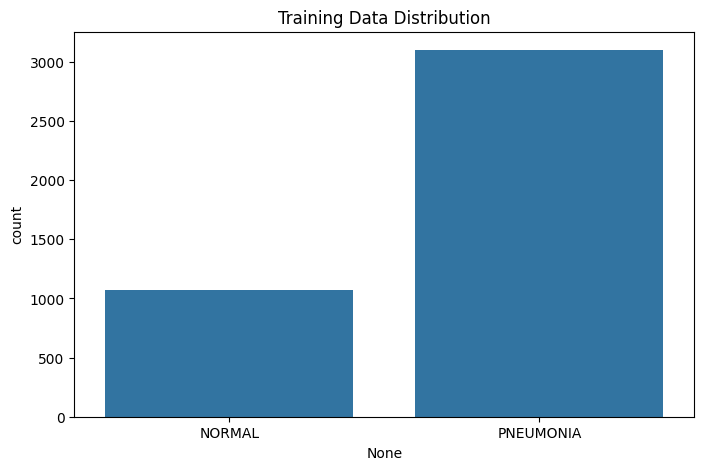

In [ ]:
# --- This is the new visualization code ---

# 1. Get all the labels from the generator
# This is an array of 0s and 1s (e.g., [0, 1, 1, 0, ...])
all_labels = train_gen.classes

# 2. Get the mapping from number to class name
# We invert the class_indices dictionary
label_map = {v: k for k, v in train_gen.class_indices.items()}
print("Label Mapping:", label_map)
# Output will be {0: 'NORMAL', 1: 'PNEUMONIA'}

# 3. Use pandas to map the numbers to the names
# This creates a list of strings: ['NORMAL', 'PNEUMONIA', 'PNEUMONIA', ...]
l_series = pd.Series(all_labels).map(label_map)

# 4. Plot just like you did before!
plt.figure(figsize=(8, 5))
sns.countplot(x=l_series)
plt.title('Training Data Distribution')
plt.show()

Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


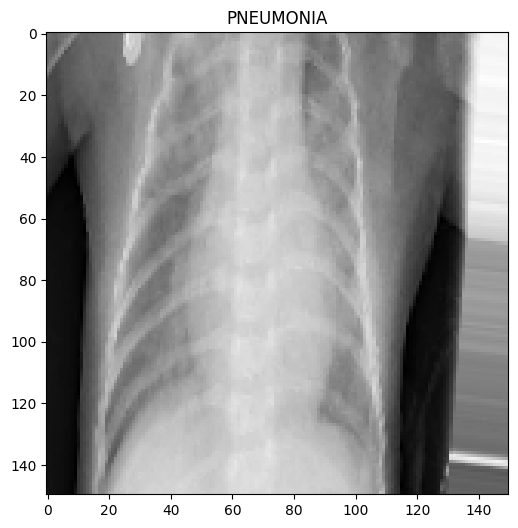

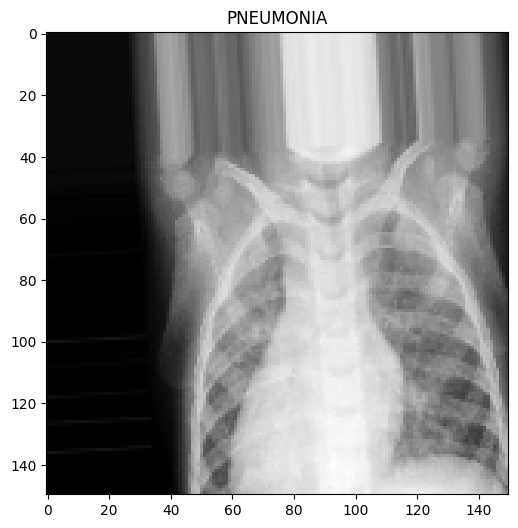

In [ ]:
label_map = train_gen.class_indices
print(f"Class mapping: {label_map}")

# 2. Create the list of labels in the *correct order*
#    This creates ['NORMAL', 'PNEUMONIA']
labels_list = list(label_map.keys())

# 3. Get one batch of data from the generator
#    images_batch will be (Batch_Size, 150, 150, 1)
#    labels_batch will be (Batch_Size,)
images_batch, labels_batch = next(train_gen)

# --- Now we can plot images from this batch ---

# 4. Plot the first image in that batch
plt.figure(figsize=(6,6))
# images_batch[0] is the first image
# .squeeze() removes the (1) color channel for plotting
plt.imshow(images_batch[0].squeeze(), cmap='gray')

# labels_batch[0] is the label (e.g., 0.0 or 1.0)
# We convert it to an integer to use as an index
image_label_index = int(labels_batch[0])
plt.title(labels_list[image_label_index])
plt.show()

# 5. Plot the second image in that batch
plt.figure(figsize=(6,6))
plt.imshow(images_batch[1].squeeze(), cmap='gray')
image_label_index = int(labels_batch[1])
plt.title(labels_list[image_label_index])
plt.show()

In [ ]:
# You DO NOT need the x_train, y_train lists.
# Instead, you pass the generators directly to model.fit()

# Example:
model = Sequential()
model.add(Conv2D(32,(3,3), strides=(1, 1), padding='same'))
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))
# ...all your other model.add() layers...
model.add(Flatten())
model.add(Dense(units=1, activation='sigmoid'))

# And this line is also essential
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
#Normalize the data
train_datagen = ImageDataGenerator(
    rescale=1./255,  # <-- THIS LINE IS DOING THE NORMALIZATION
    rotation_range=20,
    # ...other augmentations
)

In [14]:
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization

# --- This is the corrected model definition ---

model = Sequential()

# Block 1
# Corrected strides=1 to strides=(1, 1)
model.add(Conv2D(32, (3, 3), strides=(1, 1), padding='same', activation='relu', input_shape=(150, 150, 1)))
model.add(BatchNormalization())
# Corrected strides=2 to strides=(2, 2)
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))

# Block 2
# Corrected strides=1 to strides=(1, 1)
model.add(Conv2D(64, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model.add(Dropout(0.1))
model.add(BatchNormalization())
# Corrected strides=2 to strides=(2, 2)
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))

# Block 3
# Corrected strides=1 to strides=(1, 1)
model.add(Conv2D(64, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model.add(BatchNormalization())
# Corrected strides=2 to strides=(2, 2)
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))

# Block 4
# Corrected strides=1 to strides=(1, 1)
model.add(Conv2D(128, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
# Corrected strides=2 to strides=(2, 2)
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))

# Block 5
# Corrected strides=1 to strides=(1, 1)
model.add(Conv2D(256, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
# Corrected strides=2 to strides=(2, 2)
model.add(MaxPool2D((2, 2), strides=(2, 2), padding='same'))

# Fully Connected (Classifier) Head
model.add(Flatten())
model.add(Dense(units=128, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(units=1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

# Print the summary to confirm everything is correct
print("Model created and compiled successfully!")
model.summary()


Model created and compiled successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 38, 38, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 38, 38, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 19, 19, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 19, 19, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 19, 19, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 19, 19, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 1,246,401 (4.75 MB)

 Trainable params: 1,245,313 (4.75 MB)

 Non-trainable params: 1,088 (4.25 KB)

In [17]:
# 'learning_rate_reduction' is the variable you just created
learning_rate_reduction = ReduceLROnPlateau(monitor='val_accuracy',patience=2,verbose=1,factor=0.3,min_lr=0.000001)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,  # Or however many you want
    steps_per_epoch=len(train_gen),
    validation_steps=len(val_gen),
    callbacks=[learning_rate_reduction]  # <-- ADD THIS LINE
)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 418s 3s/step - accuracy: 0.7776 - loss: 1.2789 - val_accuracy: 0.7430 - val_loss: 11.3838 - learning_rate: 0.0010
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 424s 3s/step - accuracy: 0.8554 - loss: 0.3435 - val_accuracy: 0.7430 - val_loss: 1.2678 - learning_rate: 0.0010
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8736 - loss: 0.2878
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
131/131 ━━━━━━━━━━━━━━━━━━━━ 396s 3s/step - accuracy: 0.8737 - loss: 0.2876 - val_accuracy: 0.7430 - val_loss: 11.7630 - learning_rate: 0.0010
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 397s 3s/step - accuracy: 0.9196 - loss: 0.1993 - val_accuracy: 0.7430 - val_loss: 4.9244 - learning_rate: 3.0000e-04
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 465s 3s/step - accuracy: 0.9454 - loss: 0.1560 - val_accuracy: 0.7440 - val_loss: 5.9007 - learning_rate: 3.0000e-04
Epoch 6/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 405s 3s/step - accuracy: 0.9430 - l

In [ ]:
# This is the correct way to evaluate your model
# It will automatically use all 624 images from your test_gen
results = model.evaluate(test_gen)

print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]}")

163/163 ━━━━━━━━━━━━━━━━━━━━ 156s 952ms/step - accuracy: 0.9574 - loss: 0.1132
Test Loss: 0.1834196150302887
Test Accuracy: 0.9300230145454407


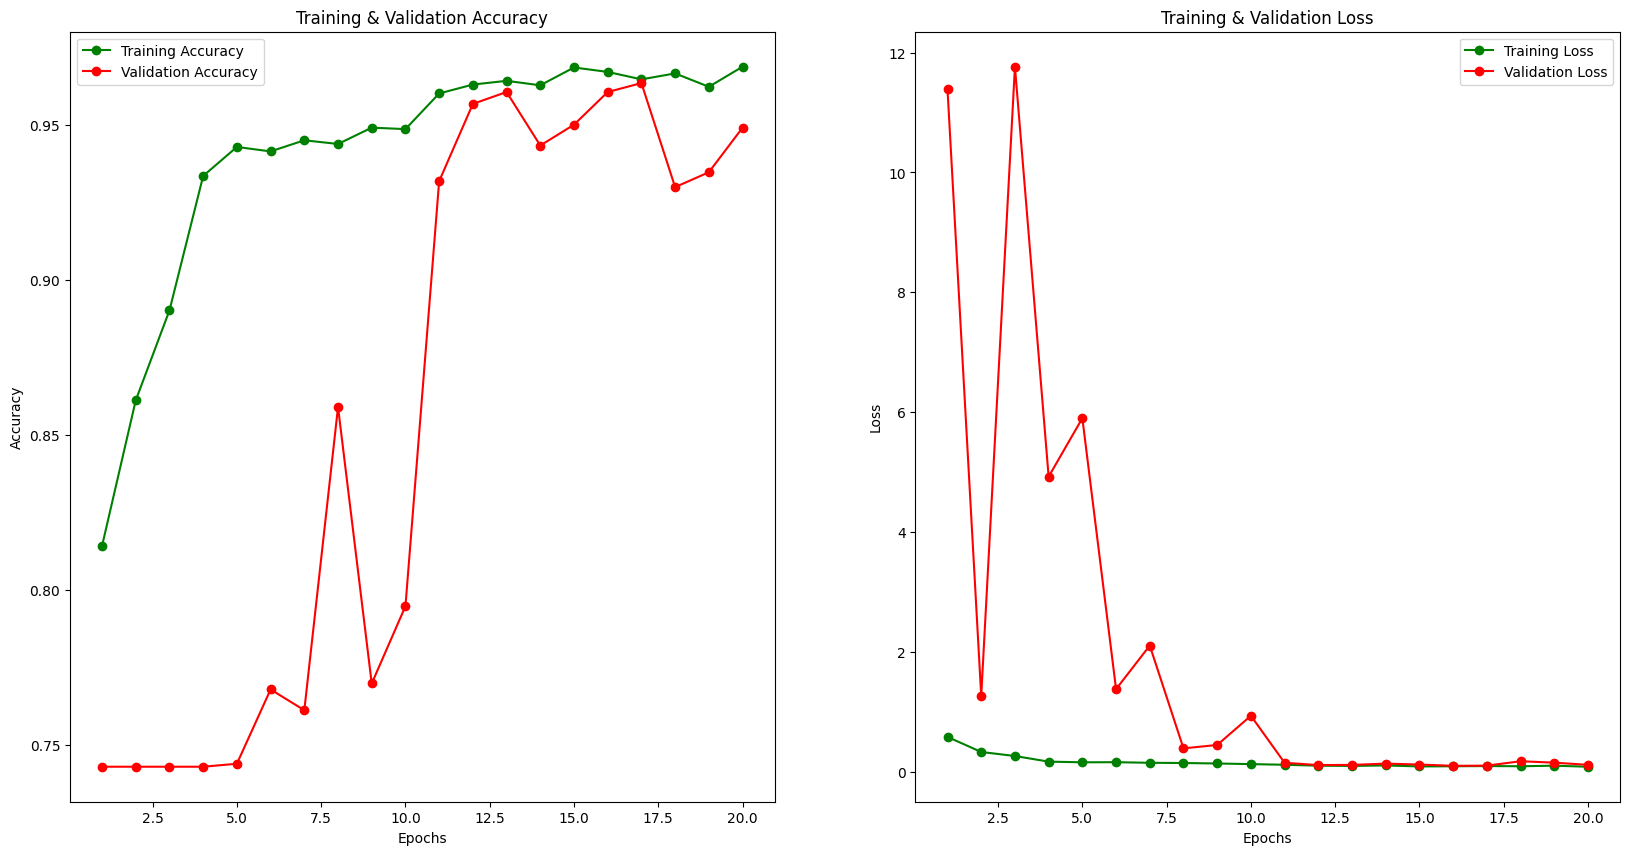

In [26]:
import matplotlib.pyplot as plt

# 1. Get the lists of results from your history object
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

# 2. Get the number of epochs that *actually ran*
num_epochs = len(train_acc)

# 3. Create the correct x-axis (e.g., [1, 2, 3, ...])
epochs_range = range(1, num_epochs + 1)

# 4. Create your plots
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(20, 10)

# --- Plot 1: Accuracy ---
ax[0].plot(epochs_range, train_acc, 'go-', label='Training Accuracy')
ax[0].plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
ax[0].set_title('Training & Validation Accuracy')
ax[0].legend()
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Accuracy')

# --- Plot 2: Loss ---
ax[1].plot(epochs_range, train_loss, 'g-o', label='Training Loss')
ax[1].plot(epochs_range, val_loss, 'r-o', label='Validation Loss')
ax[1].set_title('Training & Validation Loss')
ax[1].legend()
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss')

plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the model's raw probability predictions from the generator
#    This will be a 2D array like [[0.98], [0.12], [0.75], ...]
predictions_raw = model.predict(test_gen)

# 2. Convert probabilities to class labels (0 or 1)
#    Your logic here is correct.
predictions = (predictions_raw > 0.5).astype('int32')

# 3. Flatten the 2D array [[1], [0], [1]] into a 1D array [1, 0, 1]
#    .reshape(-1) is a simpler way to do this.
predictions = predictions.reshape(-1)

# 4. Get the *true* labels from the generator
#    This works because we set shuffle=False on test_gen
true_labels = test_gen.classes

# 5. Now you can print your first 15 predictions
print(f"First 15 Predictions: {predictions[:15]}")
print(f"First 15 True Labels:   {true_labels[:15]}")

163/163 ━━━━━━━━━━━━━━━━━━━━ 149s 899ms/step
First 15 Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
First 15 True Labels:   [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
# 'true_labels' is the variable we created from test_gen.classes
# 'predictions' is the variable from model.predict()

# We must get the class names in the correct order (0, then 1)
# You can check this with print(test_gen.class_indices)
# It will show {'NORMAL': 0, 'PNEUMONIA': 1}
class_names = ['NORMAL', 'PNEUMONIA']

print(classification_report(true_labels, predictions, target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.80      0.98      0.88      1341
   PNEUMONIA       0.99      0.91      0.95      3875

    accuracy                           0.93      5216
   macro avg       0.90      0.95      0.92      5216
weighted avg       0.94      0.93      0.93      5216



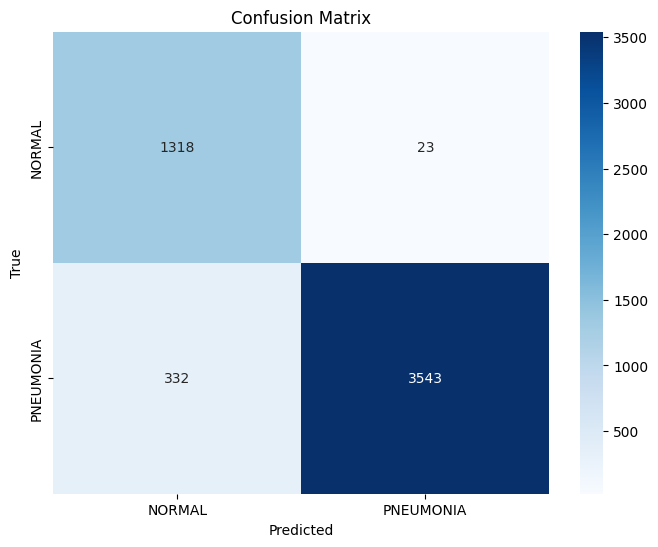

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# We assume 'true_labels' (from test_gen.classes) and 'predictions' (from model.predict)
# were created in the previous steps.

# 1. Get the class names in the correct order [0, 1]
#    Check with: print(test_gen.class_indices)
#    It should be {'NORMAL': 0, 'PNEUMONIA': 1}
class_names = ['NORMAL', 'PNEUMONIA']

# 2. Generate the confusion matrix
cm = confusion_matrix(true_labels, predictions)

# 3. Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

[[1318   23]
 [ 332 3543]]


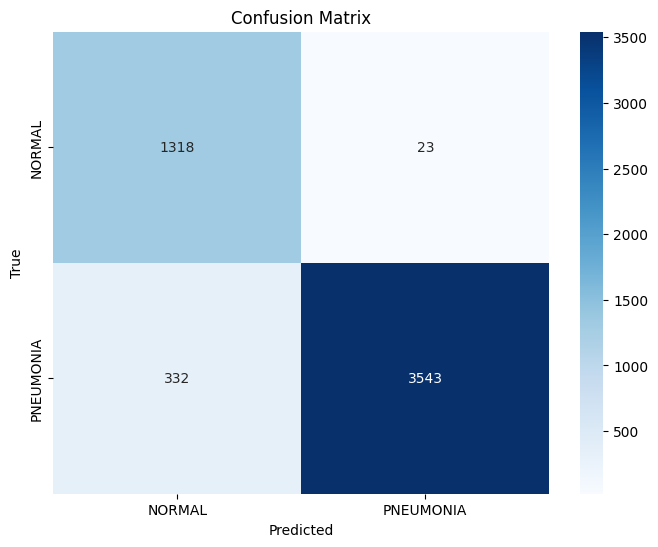

In [ ]:
class_names = ['NORMAL', 'PNEUMONIA']

# 2. Generate the confusion matrix using 'true_labels'
#    This is the corrected line:
cm = confusion_matrix(true_labels, predictions)

# 3. Print the matrix (optional)
print(cm)

# 4. Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

163/163 ━━━━━━━━━━━━━━━━━━━━ 152s 912ms/step


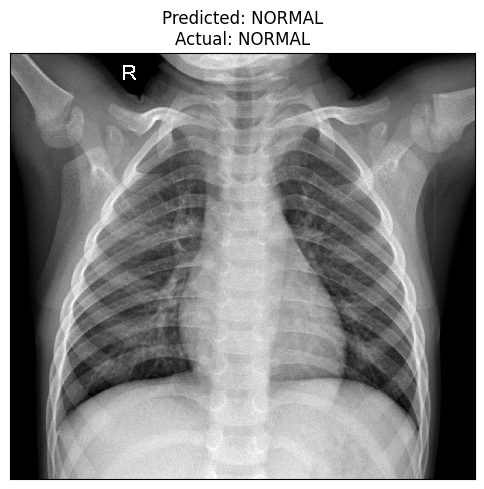

In [ ]:
import matplotlib.image as mpimg
filenames = test_gen.filenames
base_test_dir = test_gen.directory
class_names = list(test_gen.class_indices.keys())
true_labels = test_gen.classes

#Re-run predictions just in case (optional, but safe)
predictions_raw = model.predict(test_gen)
predictions = (predictions_raw > 0.5).astype('int32').reshape(-1)

# Find the indices of all correct predictions
correct_indices = np.nonzero(predictions == true_labels)[0]

# --- Plot one correct image ---

# 1. Get the index for a single correct image (e.g., the 10th one)
#    You can change '10' to any number, like 50, 100, etc.
c = correct_indices[10]

# 2. Get the filename and build the full path
img_path = filenames[c]
full_img_path = os.path.join(base_test_dir, img_path)

# 3. Read and show the image
img = mpimg.imread(full_img_path)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray', interpolation='none')
plt.xticks([])
plt.yticks([])

# 4. Get the label names (e.g., "PNEUMONIA")
pred_label_name = class_names[predictions[c]]
true_label_name = class_names[true_labels[c]]

plt.title(f"Predicted: {pred_label_name}\nActual: {true_label_name}")
plt.show()

In [ ]:
img = cv2.imread(full_img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # Convert to grayscale
img = cv2.resize(img, (150, 150))           # Resize to 150x150

# 2. Preprocess the image for the model
#    a. Normalize the pixels
img_array = np.array(img) / 255.0
#    b. Add the 'batch' and 'channel' dimensions
#       The shape becomes (1, 150, 150, 1)
img_array_expanded = np.expand_dims(img_array, axis=[0, -1])

print(f"Image shape ready for model: {img_array_expanded.shape}")



#That's perfect. The shape (1, 150, 150, 1) is exactly what the model needs to make a prediction:
#1: One image in the batch.

#150, 150: The image height and width.

#1: One grayscale channel.

#You are now ready to run the Step 3 code cell to generate the heatmap.

Image shape ready for model: (1, 150, 150, 1)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import os
import cv2

# --- Setup: Get all the necessary lists ---
print("Getting file lists and predictions...")
filenames = test_gen.filenames
base_test_dir = test_gen.directory
class_names = list(test_gen.class_indices.keys())
true_labels = test_gen.classes

# Re-run predictions to be safe
predictions_raw = model.predict(test_gen)
predictions = (predictions_raw > 0.5).astype('int32').reshape(-1)

# Find the indices of all correct predictions
correct_indices = np.nonzero(predictions == true_labels)[0]

# --- Pick one image to analyze ---
# You can change '10' to any number from your 'correct_indices'
image_index_to_analyze = correct_indices[10]
print(f"Analyzing image at index: {image_index_to_analyze}")

# 1. Get its path
img_path = filenames[image_index_to_analyze]
full_img_path = os.path.join(base_test_dir, img_path)

# 2. Load the image using cv2 (this is the original Step 2)
img = cv2.imread(full_img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # Convert to grayscale
img = cv2.resize(img, (150, 150))           # Resize to 150x150

# 3. Preprocess the image for the model
img_array = np.array(img) / 255.0
img_array_expanded = np.expand_dims(img_array, axis=[0, -1])

print(f"Image shape ready for model: {img_array_expanded.shape}")

Getting file lists and predictions...
163/163 ━━━━━━━━━━━━━━━━━━━━ 151s 922ms/step
Analyzing image at index: 10
Image shape ready for model: (1, 150, 150, 1)
